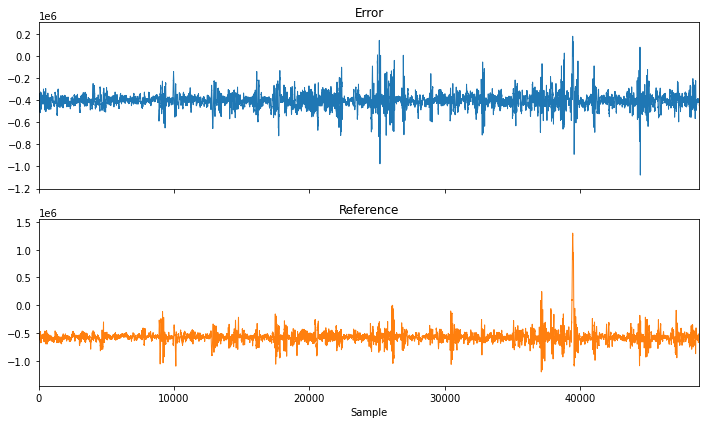

-402053.2350290817
-574950.954698124


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
from pynq import Overlay, allocate

%matplotlib inline

BUFFER_SIZE = 48828;
# DMA set to transfer 256 beats.
N = 256                 
PAD_BITS = 6
REDRAW_EVERY = 1         

overlay = Overlay("est.bit")
dma_err = overlay.axi_dma_0
dma_ref = overlay.axi_dma_1

err_plot = np.full(BUFFER_SIZE, 0, dtype=np.int32)
ref_plot = np.full(BUFFER_SIZE, 0, dtype=np.int32)

def push(buf, new):
    k = len(new)
    if k >= len(buf):
        buf[:] = new[-len(buf):]
    else:
        buf[:-k] = buf[k:]
        buf[-k:] = new

ref_buf = allocate(shape=(N,), dtype=np.int32)
err_buf = allocate(shape=(N,), dtype=np.int32)

# build the figure once
x = np.arange(BUFFER_SIZE)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
(err_line,) = ax1.plot(x, err_plot, lw=1)
(ref_line,) = ax2.plot(x, ref_plot, lw=1, color="tab:orange")
ax1.set_title("Error")
ax2.set_title("Reference")
ax2.set_xlabel("Sample")
ax1.set_xlim(0, BUFFER_SIZE)
fig.tight_layout()
plt.close(fig)          

err_average = 0;
ref_average = 0;

i = 0
try:
    while True:
        dma_ref.recvchannel.transfer(ref_buf)
        dma_err.recvchannel.transfer(err_buf)
        dma_err.recvchannel.wait()
        dma_ref.recvchannel.wait()

        err_x = np.asarray(err_buf, dtype=np.int32)
        ref_x = np.asarray(ref_buf, dtype=np.int32)

        push(err_plot, err_x)
        push(ref_plot, ref_x)
        
        err_average = np.mean(err_plot)
        ref_average = np.mean(ref_plot)
        i += 1
        if i % REDRAW_EVERY == 0:
            err_line.set_ydata(err_plot)
            ref_line.set_ydata(ref_plot)
            for ax, data in ((ax1, err_plot), (ax2, ref_plot)):
                lo, hi = int(data.min()), int(data.max())
                pad = max(1, (hi - lo) * 0.1)
                ax.set_ylim(lo - pad, hi + pad)
            
            print(err_average)
            print(ref_average)
            clear_output(wait=True)
            display(fig)

except KeyboardInterrupt:
    print("stopped")
    from scipy.io import savemat
    # chop bottom 6-bits off.
    savemat("plot_data.mat", {"err_plot": err_plot, "ref_plot": ref_plot})
    err_plot.tofile("err_plot.bin")
    ref_plot.tofile("ref_plot.bin")
    
finally:
    ref_buf.freebuffer()
    err_buf.freebuffer()

Microphone capture stopped.


In [6]:
import os
os.getcwd()

'/root/jupyter_notebooks/Untitled Folder'